# Step 1 : Dataset loading

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Mathematics dataset
df = pd.read_csv("../data/student-mat.csv", sep=";")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


# Step 2: Dataset Inspection

In [3]:
# Check dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check statistical summary
print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-nu

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


# Step 3: Exploratory Data Analysis (EDA)

Final Grade (G3) Distribution:
G3
0     38
4      1
5      7
6     15
7      9
8     32
9     28
10    56
11    47
12    31
13    31
14    27
15    33
16    16
17     6
18    12
19     5
20     1
Name: count, dtype: int64

Final Grade Statistics:
count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64


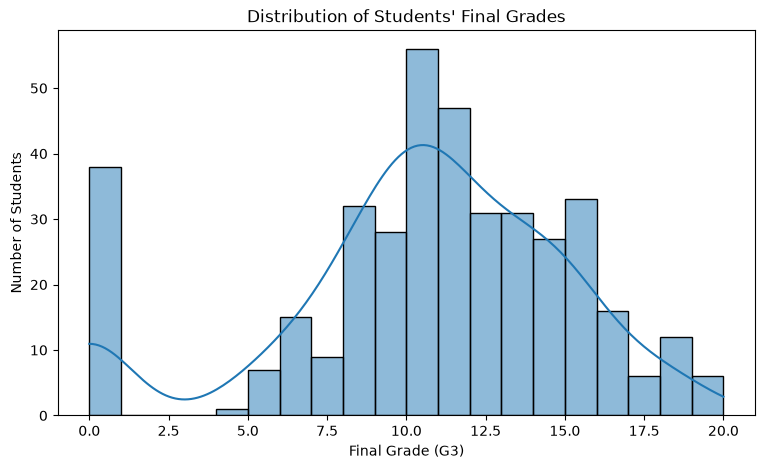

In [4]:
# Final grade distribution
print("Final Grade (G3) Distribution:")
print(df["G3"].value_counts().sort_index())

# Summary statistics
print("\nFinal Grade Statistics:")
print(df["G3"].describe())

# Visualize final grades
plt.figure(figsize=(9, 5))
sns.histplot(df["G3"], bins=20, kde=True)

plt.title("Distribution of Students' Final Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.show()

# Step 4: Create Performance Categories

Performance Class Distribution:
performance
0    130
1    265
Name: count, dtype: int64

Class Labels:
0 = At Risk
1 = Performing Well


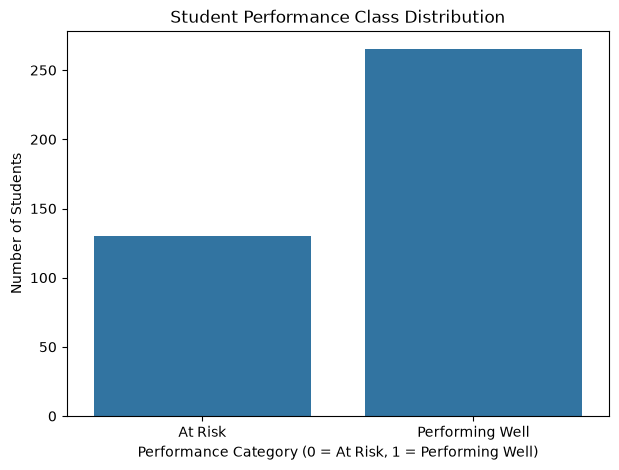

In [5]:
# Create binary target variable
df["performance"] = np.where(df["G3"] < 10, 0, 1)

# Display class distribution
print("Performance Class Distribution:")
print(df["performance"].value_counts().sort_index())

# Display class names
print("\nClass Labels:")
print("0 = At Risk")
print("1 = Performing Well")

# Visualize class distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="performance"
)

plt.title("Student Performance Class Distribution")
plt.xlabel("Performance Category (0 = At Risk, 1 = Performing Well)")
plt.ylabel("Number of Students")
plt.xticks([0, 1], ["At Risk", "Performing Well"])
plt.show()

# Step 5 – Feature Selection

In [6]:
# Separate input features and target variable

X = df.drop(columns=["G1", "G2", "G3", "performance"])

y = df["performance"]

# Display feature and target information
print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nSelected Input Features:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())

Input Features Shape: (395, 30)
Target Variable Shape: (395,)

Selected Input Features:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']

Target Distribution:
performance
1    265
0    130
Name: count, dtype: int64


# Step 6 – Split the Dataset

In [7]:
from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset split information
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Data Shape: (316, 30)
Testing Data Shape: (79, 30)

Training Target Distribution:
performance
1    212
0    104
Name: count, dtype: int64

Testing Target Distribution:
performance
1    53
0    26
Name: count, dtype: int64


# Step 7: Identify numerical and categorical columns

In [8]:
# Identify numerical and categorical columns

numerical_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object"]).columns.tolist()

print("Numerical Features:", len(numerical_features))
print(numerical_features)

print("\nCategorical Features:", len(categorical_features))
print(categorical_features)

Numerical Features: 13
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']

Categorical Features: 17
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


C:\Users\HP\AppData\Local\Temp\ipykernel_8068\2965170722.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(include=["object"]).columns.tolist()


# Step 8: Handle numerical and categorical features

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


# Step 9: Train a Logistic Regression model

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


# Step 10: Make predictions and evaluate the model

In [11]:
from sklearn.metrics import accuracy_score, classification_report

# Predict using test data
y_pred = logistic_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["At Risk", "Performing Well"]
))

Logistic Regression Results
---------------------------
Accuracy: 59.49 %

Classification Report:
                 precision    recall  f1-score   support

        At Risk       0.40      0.46      0.43        26
Performing Well       0.71      0.66      0.69        53

       accuracy                           0.59        79
      macro avg       0.56      0.56      0.56        79
   weighted avg       0.61      0.59      0.60        79



# Step 11: Train a Decision Tree model

In [12]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

decision_tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=5,
        random_state=42
    ))
])

decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


# Step 12: Evaluate the Decision Tree model

In [13]:
from sklearn.metrics import accuracy_score, classification_report

# Make predictions
y_pred_dt = decision_tree_model.predict(X_test)

# Calculate accuracy
dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Results")
print("---------------------")
print("Accuracy:", round(dt_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_dt,
    target_names=["At Risk", "Performing Well"]
))

Decision Tree Results
---------------------
Accuracy: 59.49 %

Classification Report:
                 precision    recall  f1-score   support

        At Risk       0.42      0.58      0.48        26
Performing Well       0.74      0.60      0.67        53

       accuracy                           0.59        79
      macro avg       0.58      0.59      0.58        79
   weighted avg       0.64      0.59      0.61        79



# Step 13: Train Random Forest

In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        class_weight="balanced",
        random_state=42
    ))
])

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


# Step 14: Evaluate Random Forest

In [15]:
from sklearn.metrics import accuracy_score, classification_report

# Make predictions
y_pred_rf = random_forest_model.predict(X_test)

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Results")
print("---------------------")
print("Accuracy:", round(rf_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["At Risk", "Performing Well"]
))

Random Forest Results
---------------------
Accuracy: 67.09 %

Classification Report:
                 precision    recall  f1-score   support

        At Risk       0.50      0.42      0.46        26
Performing Well       0.74      0.79      0.76        53

       accuracy                           0.67        79
      macro avg       0.62      0.61      0.61        79
   weighted avg       0.66      0.67      0.66        79



# Step 15: Train Extra Trees Classifier

In [16]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.pipeline import Pipeline

extra_trees_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", ExtraTreesClassifier(
        n_estimators=200,
        max_depth=10,
        class_weight="balanced",
        random_state=42
    ))
])

extra_trees_model.fit(X_train, y_train)

print("Extra Trees model trained successfully!")

Extra Trees model trained successfully!


# Step 16: Evaluate Extra Trees

In [17]:
from sklearn.metrics import accuracy_score, classification_report

# Make predictions
y_pred_et = extra_trees_model.predict(X_test)

# Calculate accuracy
et_accuracy = accuracy_score(y_test, y_pred_et)

print("Extra Trees Results")
print("-------------------")
print("Accuracy:", round(et_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_et,
    target_names=["At Risk", "Performing Well"]
))

Extra Trees Results
-------------------
Accuracy: 67.09 %

Classification Report:
                 precision    recall  f1-score   support

        At Risk       0.50      0.23      0.32        26
Performing Well       0.70      0.89      0.78        53

       accuracy                           0.67        79
      macro avg       0.60      0.56      0.55        79
   weighted avg       0.64      0.67      0.63        79



# Step 17: Train Support Vector Machine (SVM)

In [18]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

svm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        class_weight="balanced",
        random_state=42
    ))
])

svm_model.fit(X_train, y_train)

print("SVM model trained successfully!")

SVM model trained successfully!


# Step 18: Evaluate SVM

In [19]:
from sklearn.metrics import accuracy_score, classification_report

# Make predictions
y_pred_svm = svm_model.predict(X_test)

# Calculate accuracy
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("SVM Results")
print("-----------")
print("Accuracy:", round(svm_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_svm,
    target_names=["At Risk", "Performing Well"]
))

SVM Results
-----------
Accuracy: 63.29 %

Classification Report:
                 precision    recall  f1-score   support

        At Risk       0.44      0.42      0.43        26
Performing Well       0.72      0.74      0.73        53

       accuracy                           0.63        79
      macro avg       0.58      0.58      0.58        79
   weighted avg       0.63      0.63      0.63        79



# Step 19: Train Gradient Boosting

In [20]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline

gradient_boosting_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

gradient_boosting_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


# Step 20: Evaluate Gradient Boosting

In [21]:
from sklearn.metrics import accuracy_score, classification_report

# Make predictions
y_pred_gb = gradient_boosting_model.predict(X_test)

# Calculate accuracy
gb_accuracy = accuracy_score(y_test, y_pred_gb)

print("Gradient Boosting Results")
print("-------------------------")
print("Accuracy:", round(gb_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_gb,
    target_names=["At Risk", "Performing Well"]
))

Gradient Boosting Results
-------------------------
Accuracy: 64.56 %

Classification Report:
                 precision    recall  f1-score   support

        At Risk       0.44      0.27      0.33        26
Performing Well       0.70      0.83      0.76        53

       accuracy                           0.65        79
      macro avg       0.57      0.55      0.55        79
   weighted avg       0.61      0.65      0.62        79



# Step 21: Train HistGradientBoosting

In [22]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline

hist_gradient_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.05,
        max_leaf_nodes=15,
        random_state=42
    ))
])

hist_gradient_model.fit(X_train, y_train)

print("HistGradientBoosting model trained successfully!")

HistGradientBoosting model trained successfully!


# Step 22: Evaluate HistGradientBoosting

In [23]:
from sklearn.metrics import accuracy_score, classification_report

# Make predictions
y_pred_hist = hist_gradient_model.predict(X_test)

# Calculate accuracy
hist_accuracy = accuracy_score(y_test, y_pred_hist)

print("HistGradientBoosting Results")
print("----------------------------")
print("Accuracy:", round(hist_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_hist,
    target_names=["At Risk", "Performing Well"]
))

HistGradientBoosting Results
----------------------------
Accuracy: 62.03 %

Classification Report:
                 precision    recall  f1-score   support

        At Risk       0.40      0.31      0.35        26
Performing Well       0.69      0.77      0.73        53

       accuracy                           0.62        79
      macro avg       0.55      0.54      0.54        79
   weighted avg       0.60      0.62      0.61        79



# Step 23: Create a model comparison table

In [24]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "Extra Trees": extra_trees_model,
    "SVM": svm_model,
    "Gradient Boosting": gradient_boosting_model,
    "HistGradientBoosting": hist_gradient_model
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "At-Risk Precision": precision_score(y_test, predictions, pos_label=0, zero_division=0),
        "At-Risk Recall": recall_score(y_test, predictions, pos_label=0, zero_division=0),
        "At-Risk F1": f1_score(y_test, predictions, pos_label=0, zero_division=0)
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,Accuracy,At-Risk Precision,At-Risk Recall,At-Risk F1
0,Logistic Regression,0.595,0.400,0.462,0.429
1,Decision Tree,0.595,0.417,0.577,0.484
2,Random Forest,0.671,0.500,0.423,0.458
3,Extra Trees,0.671,0.500,0.231,0.316
4,SVM,0.633,0.440,0.423,0.431
5,Gradient Boosting,0.646,0.438,0.269,0.333
6,HistGradientBoosting,0.620,0.400,0.308,0.348


# Step 24: Visualize model accuracy

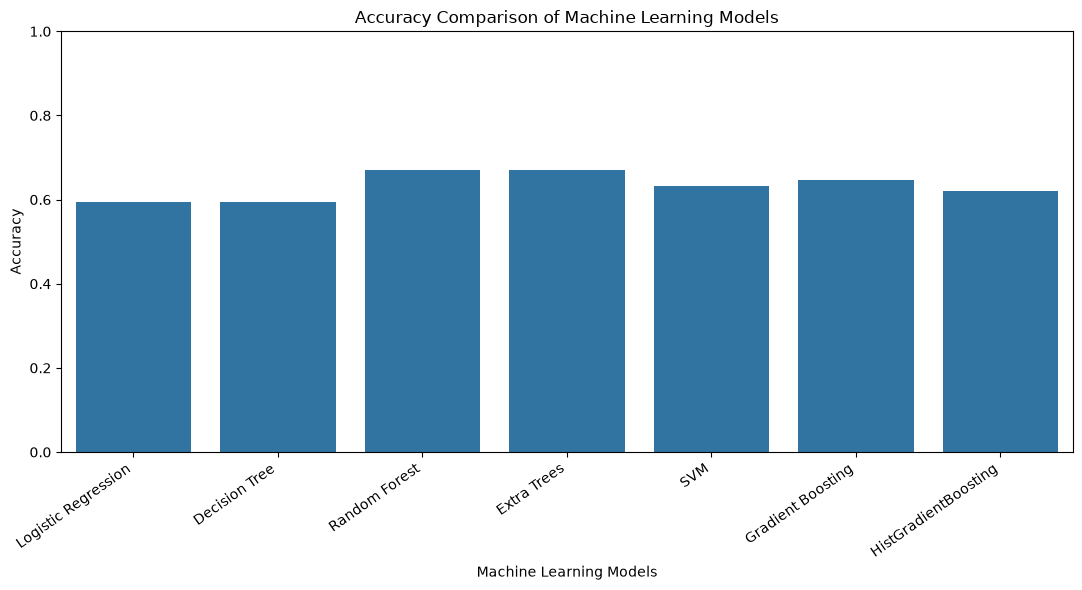

In [25]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()

# Step 25: Compare precision, recall and F1-score

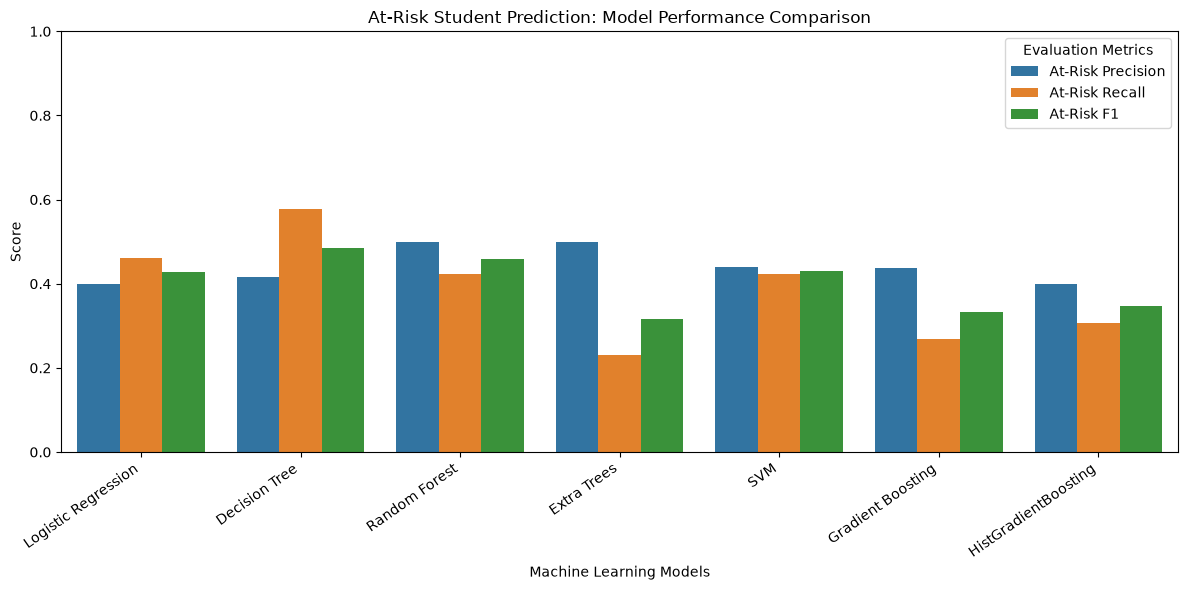

In [26]:
metrics_df = results_df.melt(
    id_vars="Model",
    value_vars=[
        "At-Risk Precision",
        "At-Risk Recall",
        "At-Risk F1"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=metrics_df,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("At-Risk Student Prediction: Model Performance Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.legend(title="Evaluation Metrics")

plt.tight_layout()
plt.show()

# Step 26: Perform Cross-Validation

In [27]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.round(3))

,Model,CV Accuracy,CV Precision,CV Recall,CV F1
0,Logistic Regression,0.684,0.790,0.726,0.756
1,Decision Tree,0.586,0.678,0.713,0.692
2,Random Forest,0.700,0.743,0.844,0.790
3,Extra Trees,0.655,0.696,0.863,0.770
4,SVM,0.652,0.725,0.778,0.749
5,Gradient Boosting,0.690,0.721,0.877,0.791
6,HistGradientBoosting,0.677,0.720,0.849,0.778


# Step 27: Calculate cross-validation metrics for At-Risk students

In [28]:
from sklearn.model_selection import cross_validate

cv_at_risk_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "precision": "precision_macro",
            "recall": "recall_macro",
            "f1": "f1_macro",
            "at_risk_recall": "recall",
        },
        n_jobs=-1
    )

    # Explicitly evaluate class 0 using a custom scorer
    from sklearn.metrics import make_scorer, recall_score, f1_score, precision_score

    at_risk_scorers = {
        "at_risk_precision": make_scorer(precision_score, pos_label=0, zero_division=0),
        "at_risk_recall": make_scorer(recall_score, pos_label=0, zero_division=0),
        "at_risk_f1": make_scorer(f1_score, pos_label=0, zero_division=0)
    }

    risk_scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=at_risk_scorers,
        n_jobs=-1
    )

    cv_at_risk_results.append({
        "Model": name,
        "At-Risk Precision": risk_scores["test_at_risk_precision"].mean(),
        "At-Risk Recall": risk_scores["test_at_risk_recall"].mean(),
        "At-Risk F1": risk_scores["test_at_risk_f1"].mean()
    })

cv_at_risk_df = pd.DataFrame(cv_at_risk_results)

display(cv_at_risk_df.round(3))

,Model,At-Risk Precision,At-Risk Recall,At-Risk F1
0,Logistic Regression,0.512,0.597,0.549
1,Decision Tree,0.393,0.328,0.348
2,Random Forest,0.561,0.404,0.467
3,Extra Trees,0.455,0.230,0.303
4,SVM,0.469,0.395,0.425
5,Gradient Boosting,0.568,0.309,0.395
6,HistGradientBoosting,0.528,0.328,0.399


# Step 28: Hyperparameter tuning

In [29]:
from sklearn.model_selection import GridSearchCV

logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [
        "balanced",
        {0: 1, 1: 1},
        {0: 2, 1: 1},
        {0: 3, 1: 1}
    ]
}

grid_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Macro F1:", round(grid_search.best_score_, 3))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters: {'classifier__C': 100, 'classifier__class_weight': {0: 2, 1: 1}}
Best Cross-Validation Macro F1: 0.658


# Step 29: Evaluate the tuned Logistic Regression model

In [30]:
# Get the best tuned model
best_logistic_model = grid_search.best_estimator_

# Make predictions on test data
y_pred_tuned = best_logistic_model.predict(X_test)

# Evaluate performance
print("Tuned Logistic Regression Results")
print("---------------------------------")

print(
    "Accuracy:",
    round(accuracy_score(y_test, y_pred_tuned) * 100, 2),
    "%"
)

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=["At Risk", "Performing Well"]
))

Tuned Logistic Regression Results
---------------------------------
Accuracy: 58.23 %

Classification Report:
                 precision    recall  f1-score   support

        At Risk       0.39      0.46      0.42        26
Performing Well       0.71      0.64      0.67        53

       accuracy                           0.58        79
      macro avg       0.55      0.55      0.55        79
   weighted avg       0.60      0.58      0.59        79



# Step 30: Compare original and tuned Logistic Regression

In [31]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "At-Risk Precision", "At-Risk Recall", "At-Risk F1"],
    "Original": [
        accuracy_score(y_test, logistic_model.predict(X_test)),
        precision_score(y_test, logistic_model.predict(X_test), pos_label=0),
        recall_score(y_test, logistic_model.predict(X_test), pos_label=0),
        f1_score(y_test, logistic_model.predict(X_test), pos_label=0)
    ],
    "Tuned": [
        accuracy_score(y_test, y_pred_tuned),
        precision_score(y_test, y_pred_tuned, pos_label=0),
        recall_score(y_test, y_pred_tuned, pos_label=0),
        f1_score(y_test, y_pred_tuned, pos_label=0)
    ]
})

display(comparison.round(3))

,Metric,Original,Tuned
0,Accuracy,0.595,0.582
1,At-Risk Precision,0.400,0.387
2,At-Risk Recall,0.462,0.462
3,At-Risk F1,0.429,0.421


# Step 31: Generate a confusion matrix for Random Forest

Random Forest Confusion Matrix:
[[11 15]
 [11 42]]


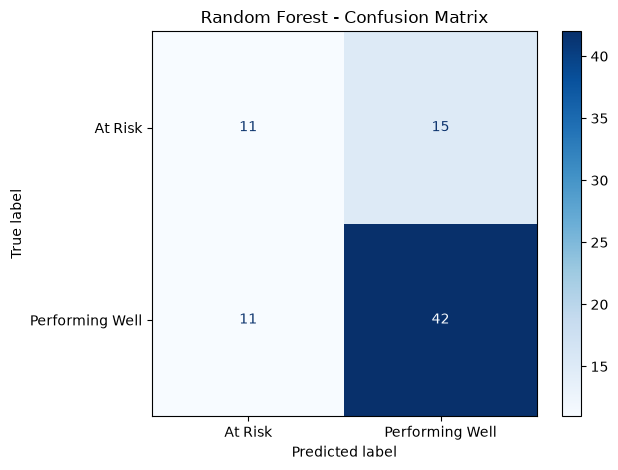

In [32]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred_rf)

print("Random Forest Confusion Matrix:")
print(cm)

# Visualize confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["At Risk", "Performing Well"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

# Step 32: Analyze feature importance

Top 15 Important Features:


,Feature,Importance
5,failures,0.085091
12,absences,0.076540
8,goout,0.045710
0,age,0.039904
11,health,0.035359
7,freetime,0.034915
10,Walc,0.034161
1,Medu,0.033094
2,Fedu,0.032745
6,famrel,0.030293


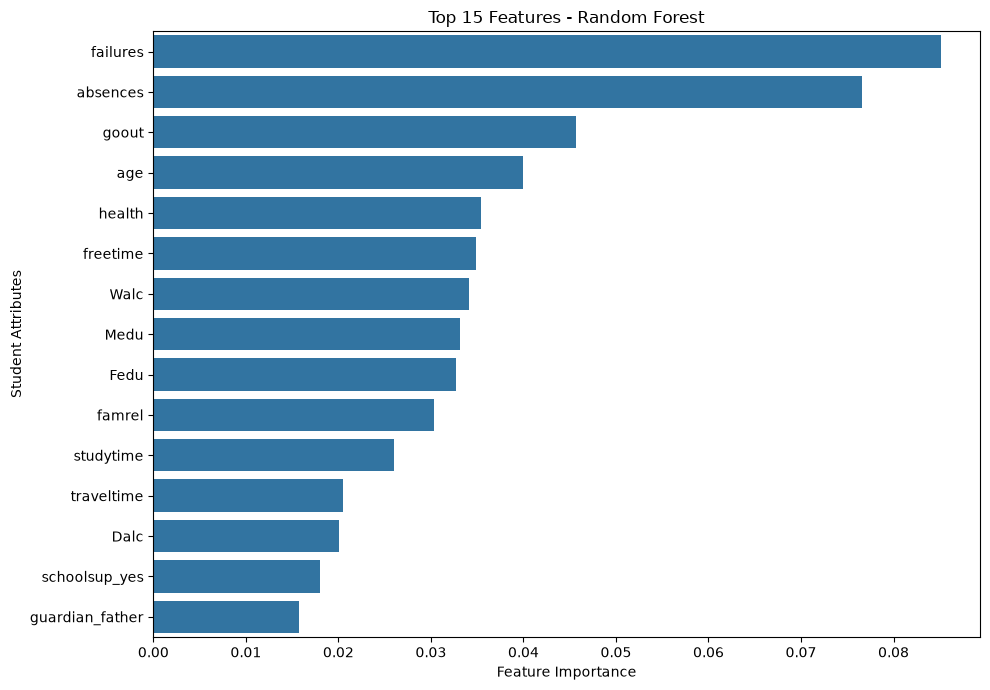

In [33]:
# Extract trained Random Forest classifier
rf_classifier = random_forest_model.named_steps["classifier"]

# Get feature importance
feature_importance = pd.DataFrame({
    "Feature": numerical_features + (
        random_forest_model.named_steps["preprocessor"]
        .named_transformers_["cat"]
        .get_feature_names_out(categorical_features).tolist()
    ),
    "Importance": rf_classifier.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Important Features:")
display(feature_importance.head(15))

# Plot feature importance
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Student Attributes")
plt.tight_layout()
plt.show()


# Step 33: Select and save the final model

In [34]:
import os
import joblib

# Create models directory if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save Random Forest model
joblib.dump(
    random_forest_model,
    "../models/random_forest_model.pkl"
)

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


# Step 34: Save the model comparison results

In [35]:

# Save model comparison results
results_df.to_csv(
    "../models/model_comparison_results.csv",
    index=False
)

# Save cross-validation results
cv_results_df.to_csv(
    "../models/cross_validation_results.csv",
    index=False
)

# Save at-risk cross-validation results
cv_at_risk_df.to_csv(
    "../models/at_risk_cv_results.csv",
    index=False
)

print("All model evaluation results saved successfully!")

All model evaluation results saved successfully!


# Step 35: Save the final evaluation graphs

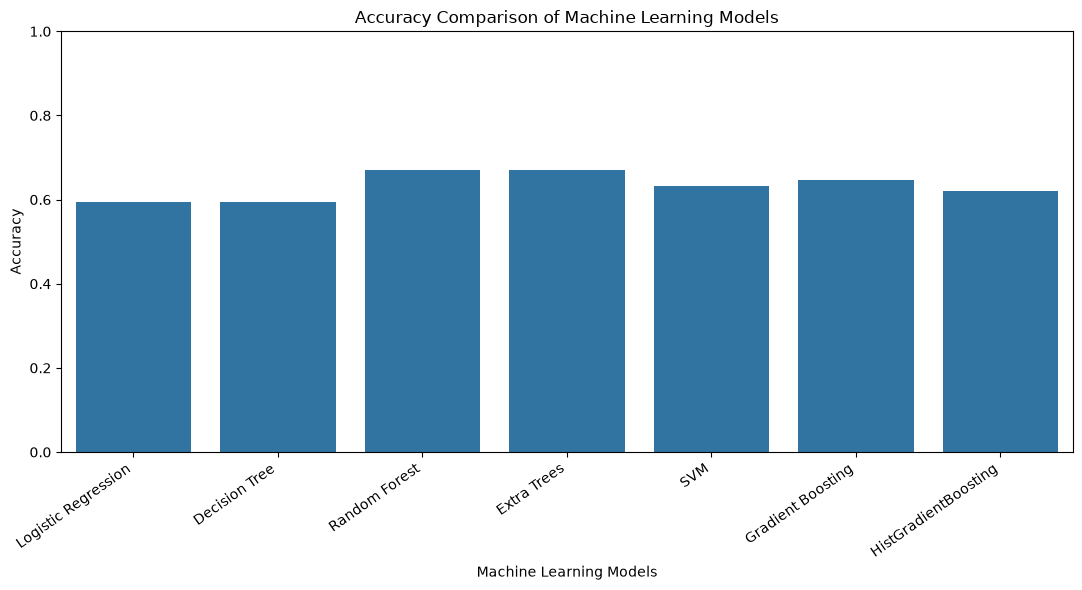

Accuracy graph saved successfully!


In [36]:
# Save accuracy comparison graph

plt.figure(figsize=(11, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=35, ha="right")

plt.tight_layout()

plt.savefig(
    "../models/accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Accuracy graph saved successfully!")

# Step 36: Save the At-Risk performance graph

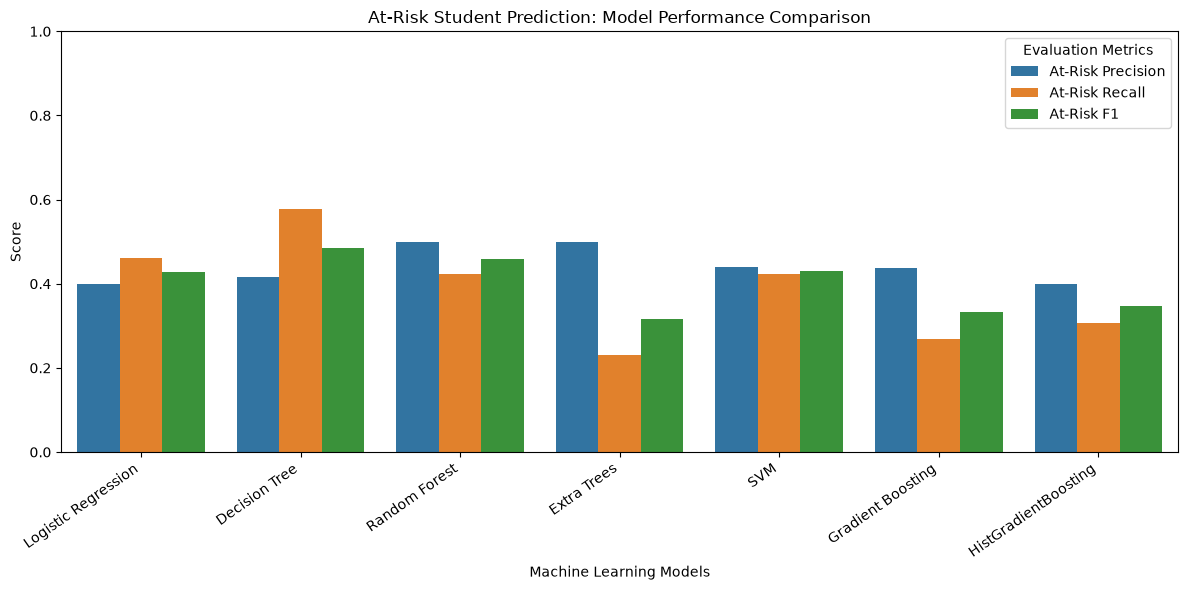

At-risk performance graph saved successfully!


In [37]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=metrics_df,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("At-Risk Student Prediction: Model Performance Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.legend(title="Evaluation Metrics")

plt.tight_layout()

plt.savefig(
    "../models/at_risk_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("At-risk performance graph saved successfully!")

# Step 37: Save the Random Forest confusion matrix

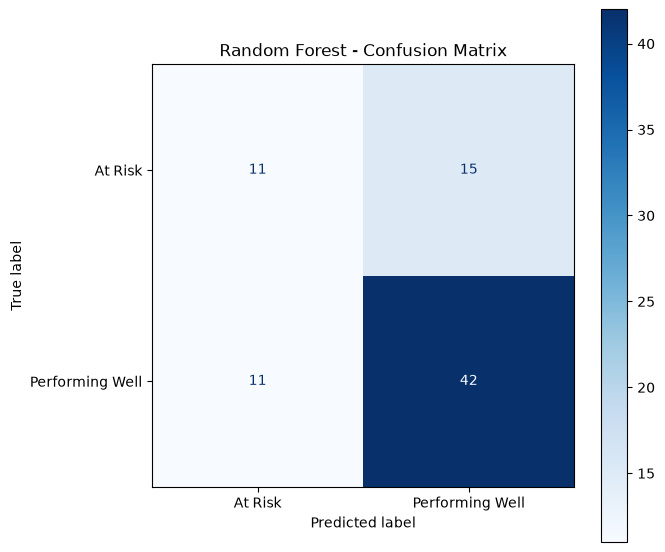

Confusion matrix saved successfully!


In [38]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["At Risk", "Performing Well"]
).plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("Random Forest - Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "../models/random_forest_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved successfully!")

# Step 38: Save the feature importance graph

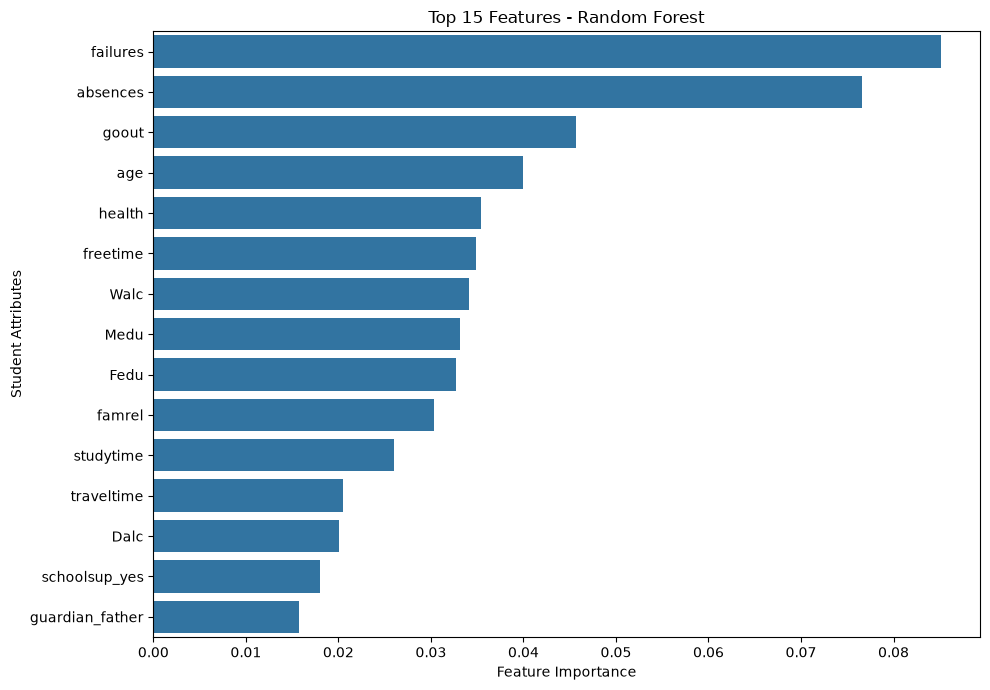

Feature importance graph saved successfully!


In [39]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Student Attributes")

plt.tight_layout()

plt.savefig(
    "../models/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Feature importance graph saved successfully!")

# Step 39: Final model selection

In [40]:
joblib.dump(
    best_logistic_model,
    "../models/tuned_logistic_model.pkl"
)

print("Tuned Logistic Regression model saved successfully!")

Tuned Logistic Regression model saved successfully!


# Step 40: Verify saved models

In [41]:
# Load saved models
loaded_rf = joblib.load("../models/random_forest_model.pkl")
loaded_logistic = joblib.load("../models/tuned_logistic_model.pkl")

# Generate predictions using loaded models
rf_predictions = loaded_rf.predict(X_test)
logistic_predictions = loaded_logistic.predict(X_test)

print("Model Verification Results")
print("--------------------------")

print("Random Forest Predictions:", len(rf_predictions))
print("Tuned Logistic Predictions:", len(logistic_predictions))

print("\nRandom Forest Sample:", rf_predictions[:10])
print("Logistic Regression Sample:", logistic_predictions[:10])

print("\nBoth saved models loaded and predicted successfully!")

Model Verification Results
--------------------------
Random Forest Predictions: 79
Tuned Logistic Predictions: 79

Random Forest Sample: [0 0 0 1 1 1 1 0 1 1]
Logistic Regression Sample: [0 0 0 1 1 1 1 0 1 1]

Both saved models loaded and predicted successfully!
